# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Hwang 2022's malignant manifold is **non-branching in geometry**: the correct topology
is a **principal curve** (ElPiGraph, non-branching by construction) fit on the *joint*
Harmony embedding — **not** a re-embedding (re-embedding an anisotropic compartment
fabricates folds). A branching PPT `tree` was tested and rejected (it over-fragments
into 4-10 spurious forks that scale with node count — noise on a near-uniform-density
cloud, not one robust bifurcation).

**Scope decision (derived, not inherited).** The manifold resolves into three lobes,
but cell cycle is **not** the lobe axis (all lobes 5-7% cycling; PDAC ~94% non-cycling)
and the developmental signatures span all three lobes rather than being confined to one,
so the whole manifold is the honest developmental object (Steele/Bischoff/Sun no-scoping
precedent). The curve is rooted at the **gastrulation-high** tip (developmental origin)
and pseudotime flows outward. **Note:** the biological *readout* on this trajectory
(Gate 2) is evaluated in 03; here we build and root the geometry.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding.
The three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored
against the shared **union** control pool and graph-smoothed (3 knn-connectivity
passes) to read geography rather than 10x per-cell dropout.

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global module means: Gast %.4f pSom %.4f Crest %.4f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

whole malignant manifold: 64399 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.26
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present
global module means: Gast -0.0045 pSom -0.0020 Crest 0.0025


### Scope decision — whole manifold vs a single lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case, scoping
justified) or spans all (Bischoff/Sun/Steele case, keep whole manifold). The three
lobes carry near-identical smoothed developmental means and the Crest-high decile is
distributed across all three (48% / 33% / 19%), while cell cycle is flat across lobes.
The proliferation split is therefore orthogonal to (and does not define) the
developmental structure, so the whole manifold is carried forward.

In [6]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'lobe'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across lobes:', frac)
print('-> developmental structure is orthogonal to the (flat) proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.33
  Crest_sm vs Gast_sm: r = -0.30
  Crest_sm vs pSom_sm: r = -0.39

per-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm  cycling
lobe                                     
0     -0.0009  -0.0023    0.0005   0.0669
1     -0.0045  -0.0036    0.0053   0.0613
2     -0.0155   0.0022    0.0033   0.0634

Crest-high decile distributed across lobes: {'1': 0.51, '0': 0.28, '2': 0.21}
-> developmental structure is orthogonal to the (flat) proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong
bending regularisation, keeping the arc smooth. The `assert` fails loudly if the curve
forks or folds.

In [8]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.71 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin. Pseudotime then flows away from it. (Whether that flow reproduces
the required Gast/pSom-origin -> terminal-Crest order is the Gate-2 question, answered
in 03.)

In [10]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0003 pSom=-0.0018 Crest=+0.0011
tip 2: Gast=-0.0152 pSom=+0.0020 Crest=+0.0029
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.656 p=0.0e+00
  pSom_sm: rho=+0.114 p=2.3e-184
  Crest_sm: rho=+0.137 p=3.2e-269
  cyc_score: rho=-0.182 p=0.0e+00


### Reorient to house style (pseudotime left -> right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis
can silently reflect an axis). This trajectory is already **horizontal** in the raw
embedding (corr(raw_umap_x, pseudotime)=+0.94), so the house transform is the **identity**
(X_umap_lin = raw_umap). The assertion confirms low pseudotime lands on the left.

In [12]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])        # identity: already horizontal
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity (already horizontal); corr(x_lin, pseudotime) = +0.94


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


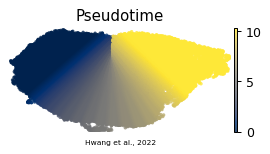

In [14]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')